# Reproducing Figure 7A & 7B of Higgins et al. (2017), *β-VAE*, in PyTorch

**Goal.** Train a β-VAE (β = 4) and a standard VAE (β = 1) with the *same* architecture, optimiser and minibatch stream on the 2D Shapes dataset (dSprites), then rebuild the two Fig. 7 panels:

| Fig. 7 row | What it shows | How it is computed here |
|---|---|---|
| column order | latents $z_i$ sorted by learnt posterior variance (last row of numbers) | $\overline{\sigma_i^2} = \frac{1}{N}\sum_n \sigma_i^2(x_n)$, ascending; last column = least informative latent ("$z_{\text{unused}}$") |
| row 1 *position* | mean $\mu_i$ as a function of the 32×32 positions, averaged over shape, scale, rotation | $\mathbb{E}[\mu_i(x)\mid \text{posX},\text{posY}]$, jet colormap, red = high |
| row 2 *scale* | mean $\mu_i$ vs. the 6 scales, one curve per shape | $\mathbb{E}[\mu_i(x)\mid \text{shape},\text{scale}]$ |
| row 3 *rotation* | mean $\mu_i$ vs. the 40 rotations, one curve per shape | $\mathbb{E}[\mu_i(x)\mid \text{shape},\text{rotation}]$ |
| rows 4–8 | decoded images while traversing a single $z_i \in [-3, 3]$, other 9 latents fixed at the inferred $\mu(x)$ of one dataset image | $\sigma(\text{dec}(z))$ |

Shape colours follow the caption: **square = red, oval = green, heart = blue**.

**Setup taken from the paper** (Table 1, row "2D shapes (VAE)", Appendix A.1):
* input 4096 (flattened 64×64×1), Bernoulli likelihood
* encoder FC 1200 → 1200, ReLU; 10 latents (diagonal Gaussian)
* decoder FC 1200 → 1200 → 1200 → 4096, Tanh
* Adagrad, learning rate $10^{-2}$

The paper does not state batch size or number of iterations; those are the two free choices below.

## 0. Configuration
On a GPU the default budget runs in minutes. On CPU, reduce `N_ITERS` (20k already gives a clear β = 4 vs β = 1 contrast). If checkpoints exist in `CKPT_DIR` and `RETRAIN = False`, training is skipped and the saved weights are loaded. (The outputs saved in this notebook come from checkpoints produced by exactly this training cell: seed 1, 20k iterations, batch 64, on CPU.)

In [1]:
import os, json, time, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec

DEVICE     = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DATA_PATH  = "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
DATA_URL   = ("https://raw.githubusercontent.com/google-deepmind/dsprites-dataset/master/"
              "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz")
CKPT_DIR   = "checkpoints"
RETRAIN    = False          # True -> ignore existing checkpoints and train from scratch

BETAS      = [4, 1]         # Fig. 7A: beta-VAE (beta=4); Fig. 7B: VAE (beta=1)
Z_DIM      = 10
LR         = 1e-2           # Adagrad, Table 1
BATCH_SIZE = 64
N_ITERS    = 20_000         # ~1.7 epochs; increase (e.g. 100k) on a GPU for cleaner factors
LOG_EVERY  = 250
SEED       = 1            # seed used for the outputs shown (see Section 7 for seeds 0-2)

torch.manual_seed(SEED); np.random.seed(SEED)
os.makedirs(CKPT_DIR, exist_ok=True)
print("device:", DEVICE)

device: cuda


## 1. Data: dSprites and its ground-truth factors
737,280 binary 64×64 images = the full Cartesian product of **shape** (3) × **scale** (6) × **rotation** (40) × **posX** (32) × **posY** (32) (colour is constant). Because the array is stored in row-major order over these factors, `mu.reshape(3, 6, 40, 32, 32, Z)` puts every inferred latent on the factor grid, so the conditional means in Fig. 7 are just averages over axes.

To keep memory small (≈377 MB instead of 3 GB) the images are bit-packed and unpacked per minibatch.

In [2]:
if not os.path.exists(DATA_PATH):
    print("downloading dSprites ..."); urllib.request.urlretrieve(DATA_URL, DATA_PATH)

LATENT_SIZES = (3, 6, 40, 32, 32)                    # shape, scale, orientation, posX, posY
FACTOR_NAMES = ["shape", "scale", "rotation", "pos. X", "pos. Y"]

_d = np.load(DATA_PATH, allow_pickle=True, encoding="latin1")
meta = _d["metadata"][()]
print("factors:", meta["latents_names"], meta["latents_sizes"])
_imgs = _d["imgs"]
packed = np.packbits(_imgs.reshape(len(_imgs), -1), axis=1)     # (737280, 512) uint8
del _imgs, _d
N = len(packed); print("images:", N, " packed bytes:", packed.nbytes / 1e6, "MB")

def get_batch(idx, device=DEVICE):
    return torch.from_numpy(np.unpackbits(packed[idx], axis=1).astype(np.float32)).to(device)

def factor_index(shape, scale, rot, x, y):
    return int(np.ravel_multi_index((shape, scale, rot, x, y), LATENT_SIZES))

# sanity check: posY indexes image rows (top -> bottom), posX indexes columns
for (nm, a, b) in [("posY", (0, 5, 0, 16, 0), (0, 5, 0, 16, 31)), ("posX", (0, 5, 0, 0, 16), (0, 5, 0, 31, 16))]:
    r0, c0 = np.nonzero(get_batch([factor_index(*a)], "cpu")[0].view(64, 64).numpy())
    r1, c1 = np.nonzero(get_batch([factor_index(*b)], "cpu")[0].view(64, 64).numpy())
    print(f"{nm} 0 -> 31 moves centroid from (row {r0.mean():.0f}, col {c0.mean():.0f}) to (row {r1.mean():.0f}, col {c1.mean():.0f})")

downloading dSprites ...
factors: ('color', 'shape', 'scale', 'orientation', 'posX', 'posY') [ 1  3  6 40 32 32]
images: 737280  packed bytes: 377.48736 MB
posY 0 -> 31 moves centroid from (row 16, col 32) to (row 48, col 32)
posX 0 -> 31 moves centroid from (row 32, col 16) to (row 32, col 48)


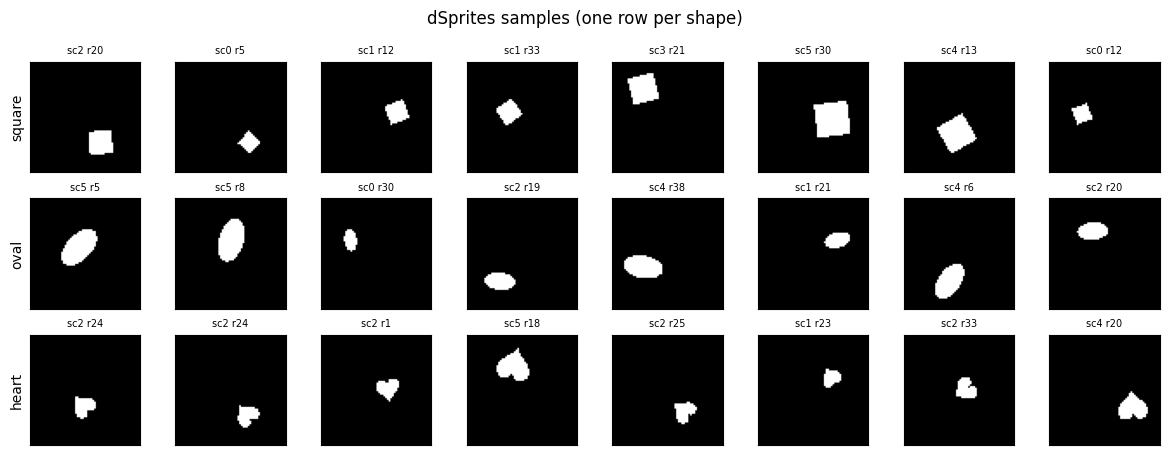

In [3]:
fig, axes = plt.subplots(3, 8, figsize=(12, 4.6))
rng = np.random.default_rng(1)
for s in range(3):
    for j in range(8):
        sc, ro, px, py = rng.integers(6), rng.integers(40), rng.integers(32), rng.integers(32)
        axes[s, j].imshow(get_batch([factor_index(s, sc, ro, px, py)], "cpu")[0].view(64, 64), cmap="gray")
        axes[s, j].set_xticks([]); axes[s, j].set_yticks([])
        axes[s, j].set_title(f"sc{sc} r{ro}", fontsize=7)
    axes[s, 0].set_ylabel(["square", "oval", "heart"][s])
plt.suptitle("dSprites samples (one row per shape)"); plt.tight_layout(); plt.show()

## 2. Model and objective

**Objective (Eq. 4 of the paper).** For each image $x$,
$$\mathcal{F}(\theta,\phi;x,\beta)=\mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]-\beta\,D_{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big),\qquad p(z)=\mathcal N(0,I).$$
β = 1 recovers the ordinary ELBO. β > 1 increases the price of every nat of information the posterior carries about $x$, which pushes the model to use as few latent dimensions as it can, each for the most "pixel-efficient" factor.

**Reconstruction term.** With a Bernoulli decoder $p_\theta(x\mid z)=\prod_j \pi_j^{x_j}(1-\pi_j)^{1-x_j}$, $\pi=\sigma(\text{logits})$, we get $\log p_\theta(x\mid z) = \sum_j x_j\log\pi_j+(1-x_j)\log(1-\pi_j)$, i.e. minus the binary cross-entropy summed over the 4096 pixels. The expectation is estimated with one reparameterised sample $z=\mu+\sigma\odot\epsilon$, $\epsilon\sim\mathcal N(0,I)$.

**KL term, from the definition.** For one coordinate, $q=\mathcal N(\mu,\sigma^2)$, $p=\mathcal N(0,1)$:
$$D_{KL}(q\|p)=\mathbb{E}_q\Big[\log\tfrac{q(z)}{p(z)}\Big]
=\mathbb{E}_q\Big[-\tfrac12\log\sigma^2-\tfrac{(z-\mu)^2}{2\sigma^2}+\tfrac{z^2}{2}\Big]
=-\tfrac12\log\sigma^2-\tfrac12+\tfrac12(\mu^2+\sigma^2),$$
using $\mathbb{E}_q[(z-\mu)^2]=\sigma^2$ and $\mathbb{E}_q[z^2]=\mu^2+\sigma^2$. Since the posterior is diagonal the total KL is the sum over the 10 coordinates. Keeping the **per-coordinate** KL is useful: a latent with KL ≈ 0 has $\mu\approx0,\sigma^2\approx1$ for every $x$, i.e. it carries no information. That is why Fig. 7 orders columns by learnt variance, with the "unused" latent at variance ≈ 1.

In [4]:
class VAE(nn.Module):
    # Table 1, '2D shapes (VAE)'
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(4096, 1200), nn.ReLU(),
                                 nn.Linear(1200, 1200), nn.ReLU(),
                                 nn.Linear(1200, 2 * z_dim))
        self.dec = nn.Sequential(nn.Linear(z_dim, 1200), nn.Tanh(),
                                 nn.Linear(1200, 1200), nn.Tanh(),
                                 nn.Linear(1200, 1200), nn.Tanh(),
                                 nn.Linear(1200, 4096))           # Bernoulli logits
    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, dim=1)
        return mu, logvar
    def decode(self, z):
        return self.dec(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)   # reparameterisation
        return self.decode(z), mu, logvar

def beta_vae_loss(logits, x, mu, logvar, beta):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / x.shape[0]
    kl_dim = 0.5 * (mu.pow(2) + logvar.exp() - 1 - logvar).mean(0)   # per-latent KL (derived above)
    kl = kl_dim.sum()
    return rec + beta * kl, rec, kl, kl_dim

## 3. Training
Both models see **exactly the same minibatches** in the same order and start from the same seed, so the only difference between panels A and B is β.

In [5]:
def ckpt_path(b): return os.path.join(CKPT_DIR, f"vae_beta{b}.pt")
HIST_PATH = os.path.join(CKPT_DIR, "hist.json")

def train_models(betas, n_iters):
    torch.manual_seed(SEED)
    models = {b: VAE().to(DEVICE) for b in betas}
    opts = {b: torch.optim.Adagrad(models[b].parameters(), lr=LR) for b in betas}
    hist = {b: [] for b in betas}
    rng = np.random.default_rng(SEED); t0 = time.time()
    for it in range(1, n_iters + 1):
        x = get_batch(np.sort(rng.integers(0, N, BATCH_SIZE)))
        for b in betas:
            logits, mu, logvar = models[b](x)
            loss, rec, kl, kl_dim = beta_vae_loss(logits, x, mu, logvar, b)
            opts[b].zero_grad(set_to_none=True); loss.backward(); opts[b].step()
            if it % LOG_EVERY == 0:
                hist[b].append(dict(it=it, rec=rec.item(), kl=kl.item(), kl_dim=kl_dim.tolist()))
        if it % (LOG_EVERY * 8) == 0 or it == n_iters:
            print(f"it {it:6d} {time.time()-t0:6.0f}s | " + " | ".join(
                f"beta={b}: rec {hist[b][-1]['rec']:6.1f}  KL {hist[b][-1]['kl']:5.2f}  "
                f"active(KL>0.1) {sum(k > 0.1 for k in hist[b][-1]['kl_dim'])}" for b in betas))
            for b in betas: torch.save(models[b].state_dict(), ckpt_path(b))
            json.dump({str(k): v for k, v in hist.items()}, open(HIST_PATH, "w"))
    return models, hist

if not RETRAIN and all(os.path.exists(ckpt_path(b)) for b in BETAS):
    models = {}
    for b in BETAS:
        models[b] = VAE().to(DEVICE); models[b].load_state_dict(torch.load(ckpt_path(b), map_location=DEVICE))
    hist = {int(k): v for k, v in json.load(open(HIST_PATH)).items()} if os.path.exists(HIST_PATH) else None
    print("loaded checkpoints from", CKPT_DIR, f"(trained for {hist[BETAS[0]][-1]['it']} iterations)" if hist else "")
else:
    models, hist = train_models(BETAS, N_ITERS)
for m in models.values(): m.eval()

it   2000     23s | beta=4: rec  124.6  KL 10.76  active(KL>0.1) 7 | beta=1: rec  118.3  KL 19.92  active(KL>0.1) 9
it   4000     45s | beta=4: rec  105.7  KL 10.31  active(KL>0.1) 6 | beta=1: rec  100.6  KL 18.19  active(KL>0.1) 9
it   6000     68s | beta=4: rec  107.6  KL 10.34  active(KL>0.1) 5 | beta=1: rec   96.6  KL 17.30  active(KL>0.1) 7
it   8000     90s | beta=4: rec   92.4  KL 10.16  active(KL>0.1) 5 | beta=1: rec   86.3  KL 17.03  active(KL>0.1) 7
it  10000    113s | beta=4: rec  105.9  KL 10.38  active(KL>0.1) 5 | beta=1: rec   91.5  KL 17.48  active(KL>0.1) 7
it  12000    135s | beta=4: rec   93.5  KL 10.45  active(KL>0.1) 5 | beta=1: rec   80.6  KL 17.11  active(KL>0.1) 7
it  14000    157s | beta=4: rec   93.8  KL 10.71  active(KL>0.1) 5 | beta=1: rec   78.6  KL 17.09  active(KL>0.1) 7
it  16000    179s | beta=4: rec   90.9  KL 10.74  active(KL>0.1) 5 | beta=1: rec   81.9  KL 17.05  active(KL>0.1) 7
it  18000    202s | beta=4: rec   86.1  KL 10.79  active(KL>0.1) 5 | bet

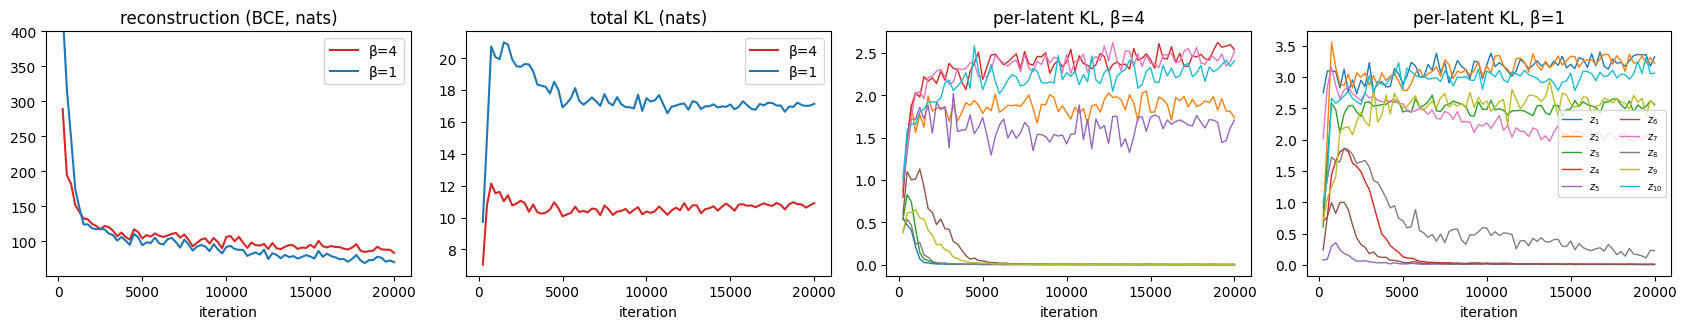

In [6]:
if hist:
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
    for b, c in zip(BETAS, ["C3", "C0"]):
        its = [h["it"] for h in hist[b]]
        ax[0].plot(its, [h["rec"] for h in hist[b]], c, label=f"β={b}")
        ax[1].plot(its, [h["kl"] for h in hist[b]], c, label=f"β={b}")
    for k, b in enumerate(BETAS):
        kd = np.array([h["kl_dim"] for h in hist[b]]); its = [h["it"] for h in hist[b]]
        for i in range(kd.shape[1]): ax[2 + k].plot(its, kd[:, i], lw=1, label=f"$z_{{{i+1}}}$")
        ax[2 + k].set_title(f"per-latent KL, β={b}"); ax[2 + k].set_xlabel("iteration")
    ax[0].set_title("reconstruction (BCE, nats)"); ax[1].set_title("total KL (nats)")
    ax[0].set_ylim(top=min(400, ax[0].get_ylim()[1])); ax[0].legend(); ax[1].legend()
    ax[3].legend(fontsize=7, ncol=2); [a.set_xlabel("iteration") for a in ax[:2]]
    plt.tight_layout(); plt.show()

## 4. Inference on the whole dataset
Encode all 737,280 images once and keep $\mu(x)$ and $\sigma^2(x)$. Every row of Fig. 7 except the traversals is a function of these two arrays.

In [7]:
@torch.no_grad()
def encode_all(model, bs=4096):
    mus, vs = [], []
    for s in range(0, N, bs):
        mu, logvar = model.encode(get_batch(np.arange(s, min(s + bs, N))))
        mus.append(mu.cpu()); vs.append(logvar.exp().cpu())
    return torch.cat(mus).numpy(), torch.cat(vs).numpy()

enc = {}
for b in BETAS:
    t = time.time(); enc[b] = encode_all(models[b])
    mv = enc[b][1].mean(0)
    print(f"beta={b}: mean posterior variance per latent (z1..z10):", np.round(mv, 2),
          f"  [{time.time()-t:.0f}s]")

beta=4: mean posterior variance per latent (z1..z10): [0.97 0.03 0.97 0.01 0.06 0.97 0.01 0.97 0.97 0.02]   [8s]
beta=1: mean posterior variance per latent (z1..z10): [0.   0.   0.01 0.91 0.92 0.93 0.02 0.68 0.01 0.  ]   [8s]


## 5. Figure 7A and 7B
Columns follow the paper's layout: the 5 most informative latents (lowest mean variance) followed by the least informative one ($z_{\text{unused}}$). Latent indices are this run's own and will not match the paper's labels (they are arbitrary). Colour and y ranges are shared across columns within a panel, so a flat line or a uniform green map really means "no response". The traversal image is the same dataset example for both models (a heart, mid-scale, at the centre).

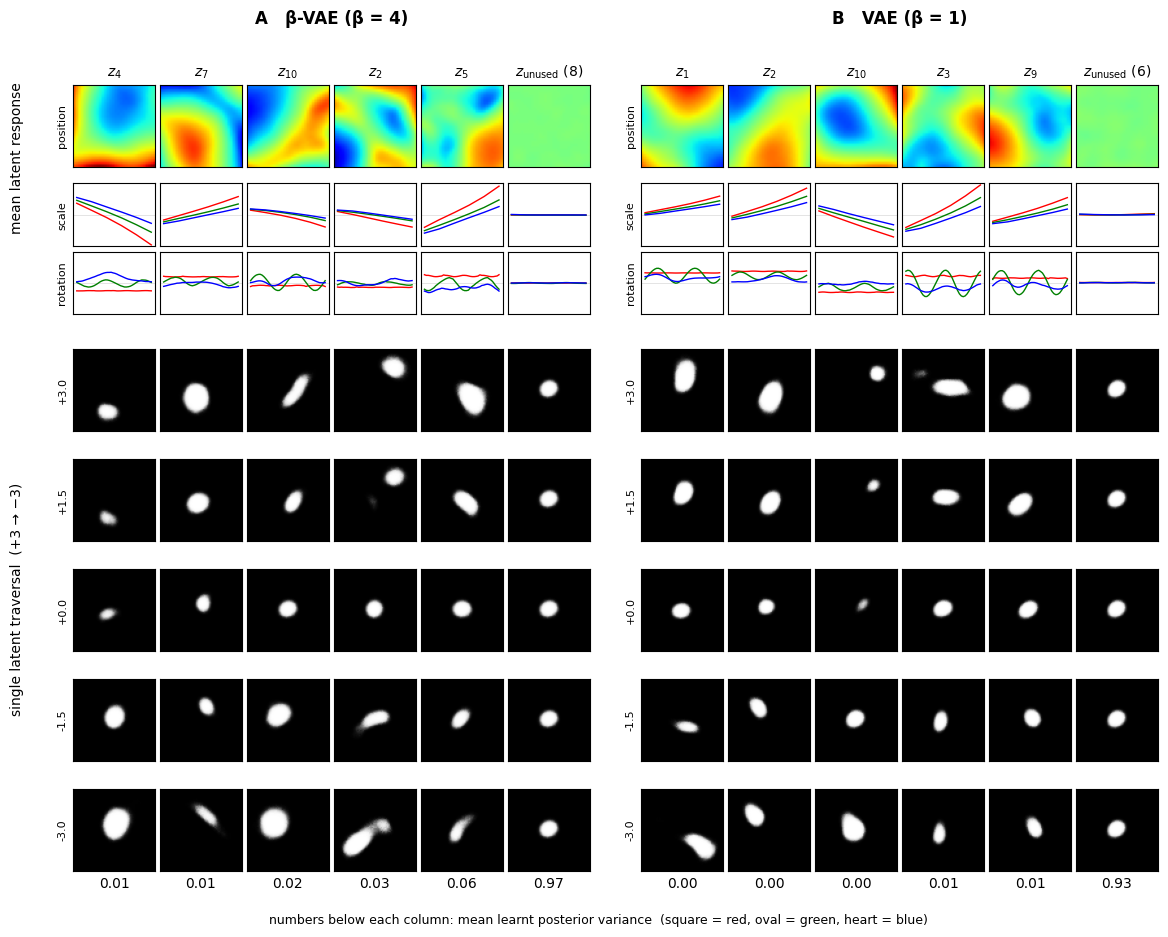

In [8]:
SHAPE_COLORS = ["red", "green", "blue"]   # square, oval, heart

def latent_responses(mu):
    g = mu.reshape(*LATENT_SIZES, -1)               # (shape, scale, rot, posX, posY, z)
    return g.mean(axis=(0, 1, 2)), g.mean(axis=(2, 3, 4)), g.mean(axis=(1, 3, 4))

@torch.no_grad()
def traverse(model, x_seed, dims, values):
    mu, _ = model.encode(x_seed[None].to(DEVICE))
    out = np.zeros((len(values), len(dims), 64, 64))
    for j, d in enumerate(dims):
        z = mu.repeat(len(values), 1); z[:, d] = torch.tensor(values, dtype=z.dtype, device=DEVICE)
        out[:, j] = torch.sigmoid(model.decode(z)).view(-1, 64, 64).cpu().numpy()
    return out

def plot_fig7_panel(fig, cell, model, mu, var, seed_idx, title, n_informative=5, n_trav=5, trav_range=3.0):
    mean_var = var.mean(0); order = np.argsort(mean_var)
    cols = list(order[:n_informative]) + [order[-1]]
    pos, scale, rot = latent_responses(mu)
    vlim = np.abs(pos[..., cols]).max()
    clim = 1.05 * max(np.abs(scale[..., cols]).max(), np.abs(rot[..., cols]).max())
    values = np.linspace(trav_range, -trav_range, n_trav)              # +3 on top, -3 at bottom
    trav = traverse(model, get_batch([seed_idx], "cpu")[0], cols, values)
    n = len(cols)
    gs = GridSpecFromSubplotSpec(4 + n_trav, n, subplot_spec=cell, hspace=0.06, wspace=0.06,
                                 height_ratios=[1.0, 0.6, 0.6, 0.12] + [1.0] * n_trav)
    for j, d in enumerate(cols):
        lbl = rf"$z_{{\rm unused}}$" + f" ({d+1})" if j == n - 1 else rf"$z_{{{d+1}}}$"
        ax = fig.add_subplot(gs[0, j])
        ax.imshow(pos[..., d].T, cmap="jet", vmin=-vlim, vmax=vlim)   # rows=posY, cols=posX (image coords)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(lbl, fontsize=10)
        if j == 0: ax.set_ylabel("position", fontsize=8)
        for r, (resp, name) in enumerate([(scale, "scale"), (rot, "rotation")], start=1):
            ax = fig.add_subplot(gs[r, j])
            for s in range(3): ax.plot(resp[s, :, d], color=SHAPE_COLORS[s], lw=1)
            ax.axhline(0, color="0.85", lw=0.5, zorder=0)
            ax.set_ylim(-clim, clim); ax.set_xticks([]); ax.set_yticks([])
            if j == 0: ax.set_ylabel(name, fontsize=8)
        for r in range(n_trav):
            ax = fig.add_subplot(gs[4 + r, j])
            ax.imshow(trav[r, j], cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
            if j == 0: ax.set_ylabel(f"{values[r]:+.1f}", fontsize=8)
            if r == n_trav - 1: ax.set_xlabel(f"{mean_var[d]:.2f}", fontsize=10)
    t = fig.add_subplot(gs[0, :], frameon=False); t.set_xticks([]); t.set_yticks([])
    t.set_title(title + "\n\n", fontsize=12, fontweight="bold")
    return cols

SEED_IDX = factor_index(2, 3, 5, 16, 16)    # heart, scale 3, rotation 5, centre
fig = plt.figure(figsize=(14, 10.5))
outer = fig.add_gridspec(1, 2, wspace=0.10)
cols_used = {}
for k, (b, title) in enumerate([(4, "A   β-VAE (β = 4)"), (1, "B   VAE (β = 1)")]):
    mu, var = enc[b]
    cols_used[b] = plot_fig7_panel(fig, outer[k], models[b], mu, var, SEED_IDX, title)
fig.text(0.085, 0.80, "mean latent response", rotation=90, ha="center", va="center", fontsize=10)
fig.text(0.085, 0.38, "single latent traversal  (+3 → −3)", rotation=90, ha="center", va="center", fontsize=10)
fig.text(0.5, 0.07, "numbers below each column: mean learnt posterior variance  "
         "(square = red, oval = green, heart = blue)", ha="center", fontsize=9)
fig.savefig("figure7_AB_reproduction.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. A quantitative companion to the figure
Fig. 7 is qualitative. To read it more objectively, for each latent $i$ and factor $k$ compute
$$S_{ik}=\frac{\operatorname{Var}_{v_k}\big(\mathbb{E}[\mu_i\mid v_k]\big)}{\operatorname{Var}(\mu_i)},$$
the fraction of $\mu_i$'s variance explained by factor $k$ alone (a first-order Sobol index; it is exact here because the dataset is the full factorial grid, so the factors are independent and uniform). A disentangled code has one dominant entry per active row. Rotation is the exception: $\mathbb{E}[\mu_i\mid \text{rot}]$ averages over shapes with different symmetries, which can cancel out, so rotation latents can score low here even when the per-shape curves in Fig. 7 oscillate clearly.

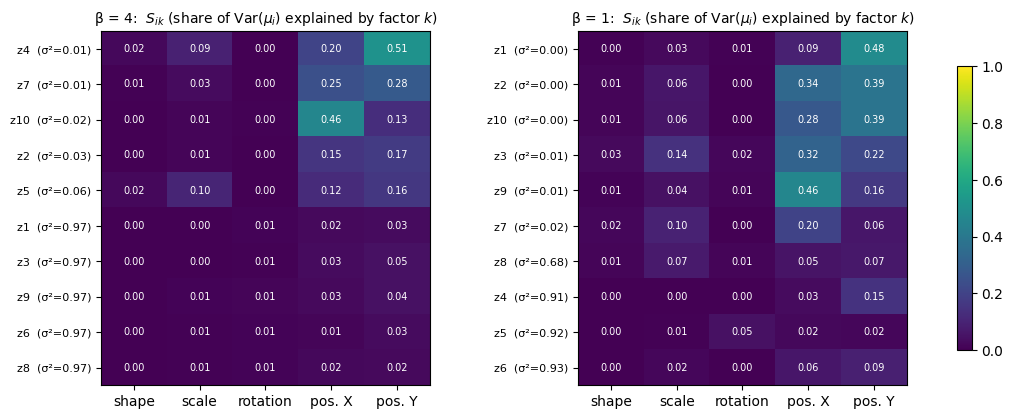

In [9]:
def factor_sensitivity(mu):
    g = mu.reshape(*LATENT_SIZES, -1)
    tot = g.reshape(-1, g.shape[-1]).var(0) + 1e-8
    return np.stack([g.mean(axis=tuple(a for a in range(5) if a != k)).var(0) / tot for k in range(5)]).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fig.subplots_adjust(wspace=0.45)
for ax, b in zip(axes, BETAS):
    mu, var = enc[b]; order = np.argsort(var.mean(0))
    S = factor_sensitivity(mu)[order]
    im = ax.imshow(S, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(5)); ax.set_xticklabels(FACTOR_NAMES)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"z{i+1}  (σ²={var.mean(0)[i]:.2f})" for i in order], fontsize=8)
    for r in range(S.shape[0]):
        for c in range(5):
            ax.text(c, r, f"{S[r, c]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if S[r, c] < 0.6 else "black")
    ax.set_title(f"β = {b}:  $S_{{ik}}$ (share of Var($\\mu_i$) explained by factor $k$)", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

## 7. Reading the result
**What this run reproduces (outputs above: seed 1, 20k iterations, batch 64, CPU).**

* **β = 4 learns a sparser code.** The unused latents sit at posterior variance ≈ 0.96–0.98, meaning they collapsed to the prior and carry no information (flat curves, uniform green maps, traversals that change nothing). This is the paper's "$z_{\text{unused}}$" column.
* **Rotation latents with symmetry-matched frequencies.** In β = 4, two latents ($z_3$, $z_2$) respond mainly to rotation, phase-shifted against each other like a cos/sin pair, as Sec. 4.1 describes. An FFT of their rotation curves over the 2π sweep gives the **square (red) 4 cycles** (π/2 symmetry, tiny amplitude), the **oval (green) 2 cycles** (π symmetry, large amplitude) and the **heart (blue) 2 cycles**. The paper reports 1 cycle for the heart (2π symmetry). Here the model has apparently not resolved the heart's up/down orientation at 64×64 and treats it as nearly π-symmetric. β = 1 also has a rotation-dominated latent ($z_{10}$; the paper likewise notes VAE's $z_9$ learnt rotation), but it is mixed with a strong scale slope.
* **Traversals: β = 4 mostly stays on the data manifold, β = 1 often does not.** For β = 4, traversals translate, grow or rotate a single object; only at the −3 extreme do some position/rotation units smear the shape. For **β = 1**, traversals of $z_1$, $z_8$, $z_9$, $z_{10}$ produce smeared, split or multi-blob images, the failure mode visible in Fig. 7B. Its latents also respond to several factors at once (e.g. $z_{10}$: rotation and scale; $z_8$, $z_9$: position and scale).
* **Reconstruction vs. disentanglement trade-off.** β = 1 reaches lower reconstruction error (≈ 75 vs ≈ 90 nats) with a larger KL (≈ 15 vs ≈ 10 nats), as Sec. 4 predicts.

**What it does not reproduce yet.** In the paper, β = 4 has *one* latent each for X, Y and scale, aligned with the image axes. Here, position and scale are shared across three latents (their position maps are tilted gradients and each has a scale slope). This is a known local optimum for β-VAE on dSprites. It depends strongly on the random seed and on training length (Locatello et al., 2019, *Challenging Common Assumptions…*, report large seed variance; Burgess et al., 2018, *Understanding disentangling in β-VAE*, add capacity annealing partly to fix this). Fig. 7A is a single, presumably good run trained much longer than 1.7 epochs.

**Seed robustness (identical protocol, 20k iterations each).** "Active" = mean posterior variance < 0.5. "Best X / Y / scale" = the largest $S_{ik}$ from Section 6 over all latents.

| seed | β | active latents | best X | best Y | best scale | rotation-dominated latent(s) |
|---|---|---|---|---|---|---|
| 0 | 4 | 4 | 0.70 | 0.57 | 0.03 | 1 |
| 0 | 1 | 6 | 0.54 | 0.57 | 0.25 | 2 (also mixed with position/scale) |
| **1** | **4** | **5** | 0.58 | 0.73 | 0.13 | **2 (cos/sin-like pair)** |
| 1 | 1 | 5 | 0.84 | 0.83 | 0.14 | 1–2 (mixed) |
| 2 | 4 | 4 | 0.46 | 0.42 | 0.05 | 1 |
| 2 | 1 | 5 | 0.43 | 0.72 | 0.24 | mixed |

Seed 1 is shown because it is the one whose β = 4 panel is closest to Fig. 7A; that choice is a form of selection, worth stating in a write-up. Two findings hold across all three seeds: β = 4 prunes to 4–5 latents, and its rotation unit(s) are less mixed with scale/position than β = 1's (judged from the panels). The finding that does *not* hold is that β = 4 is always better on position. With this short budget, β = 1 can land on cleaner X/Y axes (seed 1). To get closer to the paper, train longer (e.g. `N_ITERS = 200_000` on a GPU) and/or run several seeds and pick by the Sec. 3 disentanglement metric rather than by eye.


## 8. Things to think about / try next
1. **Why the variance ordering works.** The paper sorts columns by mean posterior variance, not by KL. Show from the per-coordinate KL formula that, for fixed $\mathbb{E}[\mu^2]$, KL is decreasing in $\sigma^2$ on $(0,1]$. When could the two orderings disagree?
2. **Rotation as two latents.** The paper reports two rotation latents behaving like $\cos$ and $\sin$, with oscillation frequency matching each shape's symmetry (2π heart, π oval, π/2 square). Why can a single real-valued Gaussian latent *not* represent a circular factor continuously? (Hint: think of what a continuous map from the circle into ℝ must do.)
3. **β sweep.** Train β ∈ {1, 2, 4, 8, 16} and plot the number of active latents and the reconstruction error against β. Fig. 6 (right) predicts an inverted-U for disentanglement. Where does your curve start dropping factors, and which factor goes first (the one with the smallest pixel-space effect)?
4. **Implement the paper's disentanglement metric (Sec. 3).** Fix one factor, sample pairs of images that share it, average $|z^{(1)}-z^{(2)}|$ over $L$ pairs, and train a linear classifier to predict which factor was fixed. Compare your β = 4 and β = 1 scores with Fig. 6 (99.2% vs 61.6%).